In [1]:
import duckdb as db
import polars as pl
import os, glob, sys
import numpy as np
import matplotlib.pyplot as plt

sys.path.insert(0, os.path.join("..", "..", "src"))
from cfg import DROP, STD_COLS, COUNT_COLS, SHORT, HERE, DATASET, PROCESSED, DB_PATH, load_extensions

In [5]:
conn = db.connect(database=DB_PATH)
metrics_raw_long = conn.execute("SELECT timestamp, short_name, value FROM metrics_raw").pl()
noon_reports = conn.execute("SELECT * FROM noon_reports").pl()
jan25 = conn.execute("SELECT * FROM jan25").pl()
metrics_reg = conn.execute("SELECT * FROM metrics_registration").pl()
metrics_wide = conn.execute("SELECT * FROM metrics_wide").pl()
conn.close()

In [14]:
metrics_reg.group_by(by="source_name").agg(pl.col("short_name"))

by,short_name
str,list[str]
"""Instrument Torquemeter""","[""shaft_rpm"", ""shaft_revs"", … ""fo_kgh""]"
"""Instrument Anemometer""","[""wind_rel_kn"", ""wind_rel_deg""]"
"""Provider MB""","[""mb_wind_kn"", ""mb_wind_deg"", … ""s_cur_n""]"
"""Instrument GPS 1""","[""sog_kn""]"
"""Transducer Pressure""","[""me_scav_bar""]"
…,…
"""Instrument RPM Indicator""","[""me_tc_rpm""]"
"""Transducer Fuel Load""","[""me_load_pct""]"
"""Instrument Gyrocompass""","[""heading_deg"", ""turn_rate""]"


c:\AID Project\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


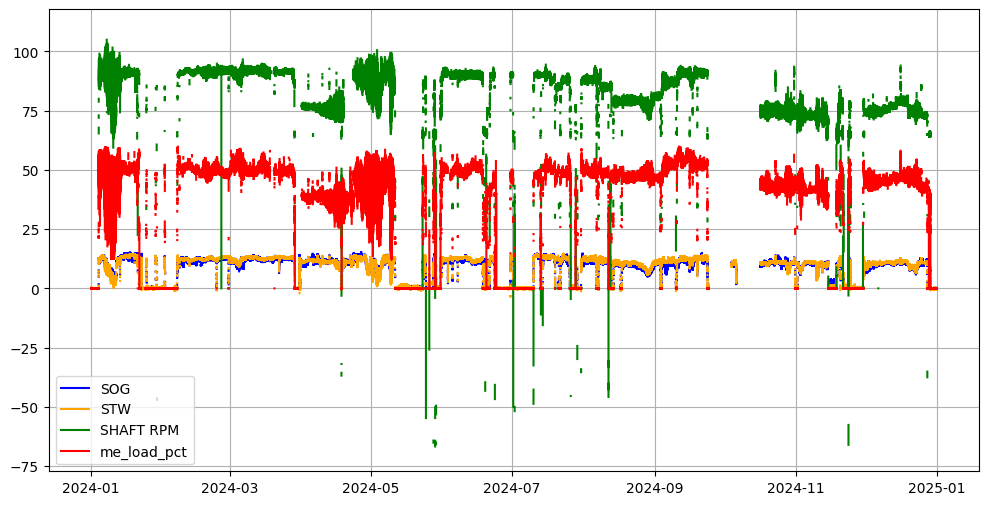

In [9]:
plt.figure(figsize=(12, 6))
plt.grid(True)
plt.plot(metrics_wide["timestamp"].to_numpy(), metrics_wide["sog_kn"].to_numpy(), color = "blue", label = "SOG")
plt.plot(metrics_wide["timestamp"].to_numpy(), metrics_wide["stw_kn"].to_numpy(), color = "orange", label = "STW")
plt.plot(metrics_wide["timestamp"].to_numpy(), metrics_wide["me_rpm"].to_numpy(), color = "green", label = "SHAFT RPM")
plt.plot(metrics_wide["timestamp"].to_numpy(), metrics_wide["me_load_pct"].to_numpy(), color = "red", label = "me_load_pct")
plt.legend()
plt.show()

c:\AID Project\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


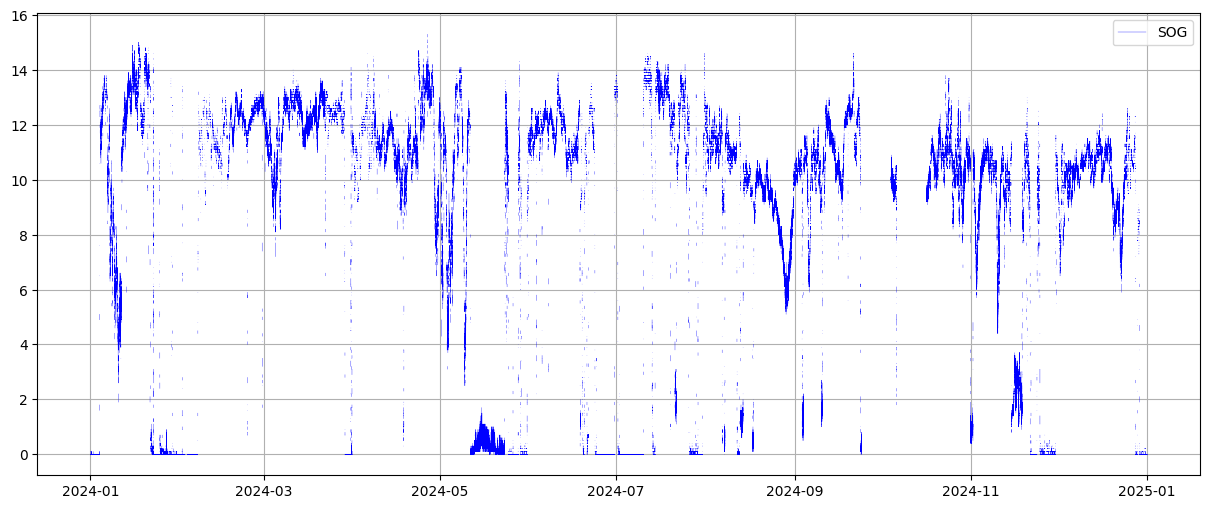

In [12]:
plt.figure(figsize=(15, 6))
plt.grid(True)
plt.plot(metrics_wide["timestamp"].to_numpy(), metrics_wide["sog_kn"].to_numpy(), color = "blue", label = "SOG", linewidth=0.25)
plt.legend()
plt.show()